In [39]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
!wget $data

--2026-10-17 11:54:00--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv.1’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.004s  

2026-10-17 11:54:00 (69.5 MB/s) - ‘course_lead_scoring_2026.csv.1’ saved [278746/278746]



In [40]:
import pandas as pd
import numpy as np

df = pd.read_csv('course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [41]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [42]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

# print(df[categorical].isnull().sum())
# print(df[numerical].isnull().sum())

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

# print(df[categorical].isnull().sum())
# print(df[numerical].isnull().sum())

# df.dtypes

In [43]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [44]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [45]:
from sklearn.metrics import roc_curve, auc, roc_auc_score

In [46]:
## Q1: use AUC to evaluate feature importance ##
# AUC goes negative if it's below 0.5

results = []
df_num = df_full_train[numerical]
y = df_full_train['converted']

for col in df_num.columns:
    # Skip non-numeric features for this example
    auc = roc_auc_score(y, df_num[col])
    
    results.append({
        "feature": col,
        "roc_auc": auc,
        "importance": abs(auc - 0.5) * 2
    })

print(results) # lead_score is highest

[{'feature': 'annual_income', 'roc_auc': 0.6095664323115277, 'importance': 0.21913286462305548}, {'feature': 'number_of_courses_viewed', 'roc_auc': 0.7209231498868814, 'importance': 0.4418462997737629}, {'feature': 'interaction_count', 'roc_auc': 0.7643636200498618, 'importance': 0.5287272400997236}, {'feature': 'lead_score', 'roc_auc': 0.78726060846883, 'importance': 0.5745212169376599}]


In [47]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [48]:
## Q2

def train(df, y, c=1.0):
    dicts = df[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=c, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

dv, model = train(df_train, y_train)

def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

y_pred = predict(df_val, dv, model)

roc_auc_score(y_val, y_pred) # 0.732

0.7318222288173319

In [49]:
import matplotlib.pyplot as plt

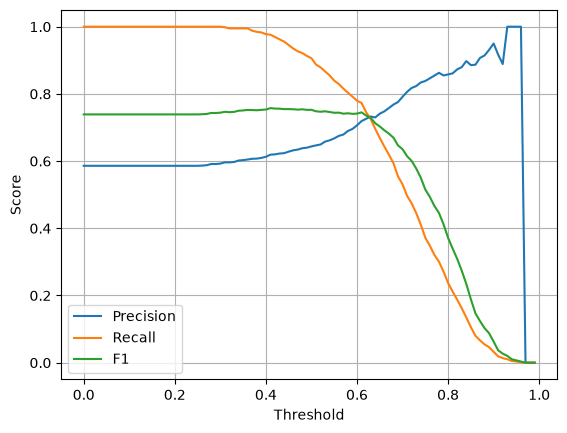

In [50]:

## Q3: Precision and Recall ##
thresholds = np.arange(0.0, 1.0, 0.01)
scores = []

for t in thresholds:
    # dv, model = train(df_train, y_train, t)
    # y_prob = predict(df_val, dv, model)

    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0
        else 0
    )

    scores.append((t, tp, fp, fn, precision, recall, f1))

df_scores = pd.DataFrame(
    scores,
    columns=['threshold', 'tp', 'fp', 'fn', 'precision', 'recall', 'f1']
)

plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')
plt.plot(df_scores.threshold, df_scores.f1, label='F1')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid()
plt.show()

# 0.63, 0.97 is intersection points

In [51]:
## Q4: F1 scores ##
print(max(df_scores.f1))
best_idx = df_scores['f1'].idxmax()
print(best_idx)
print(df_scores.loc[best_idx, ['threshold', 'f1']])

0.7576158940397352
41
threshold    0.410000
f1           0.757616
Name: 41, dtype: float64


In [52]:
!pip install tqdm

In [55]:
## Q5-6: five fold & Hyperparameters ##
from tqdm import tqdm
from sklearn.model_selection import KFold

scores = []
n_splits = 5

for C in tqdm([0.000001, 0.001, 1]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)
    scores = []
    for train_idx, val_idx in tqdm(kfold.split(df_full_train)):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
    
        y_train = df_train.converted.values
        y_val = df_val.converted.values
    
        dv, model = train(df_train, y_train, c=C)
        y_pred = predict(df_val, dv, model)
    
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)
    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|                                                   | 0/3 [00:00<?, ?it/s]
0it [00:00, ?it/s]
1it [00:00,  9.50it/s]
3it [00:00, 13.83it/s]
5it [00:00, 14.76it/s]
 33%|██████████████▎                            | 1/3 [00:00<00:00,  2.89it/s]

C=1e-06 0.617 +- 0.019



0it [00:00, ?it/s]
2it [00:00, 16.62it/s]
5it [00:00, 16.61it/s]
 67%|████████████████████████████▋              | 2/3 [00:00<00:00,  3.09it/s]

C=0.001 0.749 +- 0.010



0it [00:00, ?it/s]
2it [00:00, 18.96it/s]
5it [00:00, 14.47it/s]
100%|███████████████████████████████████████████| 3/3 [00:01<00:00,  2.97it/s]

C=1 0.732 +- 0.007
